In [28]:
#Packages needed for the notebook
using CSV 
using Serialization 
using Revise 
using LinearAlgebra 
using Random 
using PyPlot 
using NaNStatistics 
using Statistics 
using ReverseDiff
using DataFrames
using Trapz
using Optim

### Including Files

In [29]:
function correct_path(splitted_path, String)
    S=""
    for i in 1:(length(splitted_path)-1)
        S=S*splitted_path[i]*"/"
    end
    return S*String 
end

correct_path (generic function with 1 method)

In [30]:
#Including files containing the functions 
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets
includet(correct_path(split(pwd(), '/'), "Functions/Scaling Functions.jl")) #To compute MEMAR scaling and two-state state model

### Datasets

In [31]:
#Train,validation, prior from GLORI HEK293T (standard)
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
validation=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Validation_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 
#Standard in-sample test HEK293T data
test_HEK_Infer=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Test1_GLORI.bin")) 
"""Test sets for HEK293T"""
#Out-of sample: Control Condtions HEK293T with deep-sequencing
test_HEK=deserialize(correct_path(split(pwd(), '/'), "/Mapping/Data/HEK_CC_GLORI.bin"));
#Altered conditions HEK293T cell line
test_HEK_FTO=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_FTO_GLORI.bin"))
test_HEK_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_STM2457_GLORI.bin"));
#Out-of sample: Control Conditions HeLa with deep-sequencing
test_HELA=deserialize(correct_path(split(pwd(), '/'), "/Mapping/Data/HELA_CC.bin"))
#Altered conditions HeLa cell line
test_HELA_siMETTL3=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL3_GLORI.bin"));
test_HELA_siMETTL14=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL14_GLORI.bin"))
test_HELA_siYTDH=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siYTHDF2_GLORI.bin"))
test_HELA_HPX=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_Hypoxia_GLORI.bin"))
test_HELA_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_STM2457_GLORI.bin"));


In [32]:
#Saving genes of training sequencing
gene_train=keys(train);
#Saving all transcripts of test data in control conditions (independently of the reading-depth)
gene_test_infer=keys(test_HEK_Infer); 
gene_test_HEK_CC=keys(test_HEK)
gene_test_HELA_CC=keys(test_HELA);
#Find all common tes sequences 
"""Notice thats since test_infer does not share any transcript with the train, nor will do the test in HEK293T CC and HeLa CC"""
Common_Genes=intersect(gene_test_infer,gene_test_HEK_CC, gene_test_HELA_CC); #common genes amongst test datasets

In [33]:
#Saving the genes which may have non-canonical nucleotide letters
genes_not_Infer=filtering_non_nucelotides(test_HEK_Infer)
genes_not_HEK_CC=filtering_non_nucelotides(test_HEK)
genes_not_HELA_CC=filtering_non_nucelotides(test_HELA)
#Considering the unique list of transcripts contianing non-canonical nucleotide letters
genes_not=unique!(vcat([genes_not_Infer,genes_not_HEK_CC ,genes_not_HELA_CC]...))
#=Saving as testing common genes only the ones, shared amongst all sets considered (in control conditions)
Either with or without deep sequencing, removing the transcripts containing non canonical letters=#
common_genes=setdiff(Common_Genes, genes_not); #Final common genes to perform test

The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 
The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 
The gene RNA45SN2 contain a (some) non-nucleotide(s) character(s) at position(s) [11220] corresponding to the chacracter(s): N 
The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


In [34]:
#HEK293T
Test_HEK_FTO=copy_common_only(common_genes, test_HEK_FTO, test_HEK);
Test_HEK_STM2457=copy_common_only(common_genes, test_HEK_STM2457, test_HEK);
#HeLa
Test_HELA_HPX=copy_common_only(common_genes, test_HELA_HPX,test_HELA);
Test_HELA_STM2457=copy_common_only(common_genes, test_HELA_STM2457,test_HELA;)
Test_HELA_siMETTL3=copy_common_only(common_genes, test_HELA_siMETTL3, test_HELA);
Test_HELA_siMETTL14=copy_common_only(common_genes, test_HELA_siMETTL14, test_HELA);
Test_HELA_siYTDH=copy_common_only(common_genes, test_HELA_siYTDH, test_HELA);

### Training 

In [35]:
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

### Distibution of motives (train-set):

In [36]:
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1) #d(x(s̄_T |m))
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin; label=0); #d(x(s̄_T |m̄))

### Mapping:

In [37]:
#The mapping of sequences, will not change since the exact same set of sequences is present in each test dataset
MAP_mRNA=mapping_position(test_HEK_Infer, common_genes);

### Prior definition

In [38]:
#Constant prior definition following the previous equations
Ava=[] #Initialization for the constant prior
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava) #p_0(m)
constant_prior=deepcopy(prior_HEK)
[constant_prior[a].perc_met=Ava for a in keys(constant_prior)];
#Initialization for the transcript dependent prior
P=[] 
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)] #Needed for the computation of the constant prior over T̃
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)]; #p_0^T(m)

List of DRACH motifs:

In [39]:
#List of DRACH motifs
Dict_DRACH=Dict()
[Dict_DRACH[a]=[]  for a in DRACH];

### MEMAR-C

Computing the prediction of methylated and non-methylated DRACH sites for each gieven dataset, using MEMAR-C model.

In [40]:
#Control Conditions:
score_met_ps_Infer,score_not_met_ps_Infer,_=score_ps_ds_pm_DRACH(M5, M6, test_HEK_Infer, keys(MAP_mRNA), constant_prior)
score_met_ps_HEK_CC,score_not_met_ps_HEK_CC,_=score_ps_ds_pm_DRACH(M5, M6, test_HEK, keys(MAP_mRNA), constant_prior)
score_met_ps_HELA_CC,score_not_met_ps_HELA_CC,_=score_ps_ds_pm_DRACH(M5, M6, test_HELA, keys(MAP_mRNA),constant_prior)
#Altered Methylation datasets
score_met_ps_HEK_FTO,score_not_met_ps_HEK_FTO,_=score_ps_ds_pm_DRACH(M5, M6, Test_HEK_FTO, keys(MAP_mRNA), constant_prior)
score_met_ps_MET3,score_not_met_ps_MET3,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_siMETTL3, keys(MAP_mRNA), constant_prior)
score_met_ps_MET14,score_not_met_ps_MET14,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_siMETTL14, keys(MAP_mRNA), constant_prior)
score_met_ps_YTH,score_not_met_ps_YTH,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_siYTDH, keys(MAP_mRNA), constant_prior)
score_met_ps_HELA_STM,score_not_met_ps_HELA_STM,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_STM2457, keys(MAP_mRNA), constant_prior)
score_met_ps_HEK_STM,score_not_met_ps_HEK_STM,_=score_ps_ds_pm_DRACH(M5, M6, Test_HEK_STM2457, keys(MAP_mRNA), constant_prior)
score_met_ps_HPX,score_not_met_ps_HPX,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_HPX, keys(MAP_mRNA), constant_prior);

Computing the percentage of methylated DRACH adenosine for each given dataset

In [41]:
#Control Conditions:
perc_Infer=perc_met_dataset(score_met_ps_Infer, score_not_met_ps_Infer)
perc_HEK_CC=perc_met_dataset(score_met_ps_HEK_CC, score_not_met_ps_HEK_CC)
perc_HELA_CC=perc_met_dataset(score_met_ps_HELA_CC, score_not_met_ps_HELA_CC)
#Altered Methylation datasets
perc_HEK_FTO=perc_met_dataset(score_met_ps_HEK_FTO, score_not_met_ps_HEK_FTO)
perc_MET3=perc_met_dataset(score_met_ps_MET3, score_not_met_ps_MET3)
perc_MET14=perc_met_dataset(score_met_ps_MET14, score_not_met_ps_MET14)
perc_YTH=perc_met_dataset(score_met_ps_YTH, score_not_met_ps_YTH)
perc_HELA_STM=perc_met_dataset(score_met_ps_HELA_STM, score_not_met_ps_HELA_STM)
perc_HEK_STM=perc_met_dataset(score_met_ps_HEK_STM, score_not_met_ps_HEK_STM)
perc_HPX=perc_met_dataset(score_met_ps_HPX, score_not_met_ps_HPX);

Computing Precision-Recall curves amongst all DRACH sites, and saving AUPRC values

In [42]:
#Control Conditions:
_,_, A_HEK_CC,_=plot_PR_score(vcat(score_met_ps_HEK_CC...), shuffle!(vcat(score_not_met_ps_HEK_CC...)),  "goldenrod","MEMAR-C HEK293T CC"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HELA_CC,_=plot_PR_score(vcat(score_met_ps_HELA_CC...), shuffle!(vcat(score_not_met_ps_HELA_CC...)),  "steelblue","MEMAR-C HeLa CC"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_Infer,_=plot_PR_score(vcat(score_met_ps_Infer...), shuffle!(vcat(score_not_met_ps_Infer...)),  "purple","MEMAR-C HEK293T Inference"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
#Altered Methylation datasets
_,_, A_HEK_FTO,_=plot_PR_score(vcat(score_met_ps_HEK_FTO...), shuffle!(vcat(score_not_met_ps_HEK_FTO...)),  "pink","MEMAR-C HEK293T FTO"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_MET3,_=plot_PR_score(vcat(score_met_ps_MET3...), shuffle!(vcat(score_not_met_ps_MET3...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_MET14,_=plot_PR_score(vcat(score_met_ps_MET14...), shuffle!(vcat(score_not_met_ps_MET14...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_YTH,_=plot_PR_score(vcat(score_met_ps_YTH...), shuffle!(vcat(score_not_met_ps_YTH...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HELA_STM,_=plot_PR_score(vcat(score_met_ps_HELA_STM...), shuffle!(vcat(score_not_met_ps_HELA_STM...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HEK_STM,_=plot_PR_score(vcat(score_met_ps_HEK_STM...), shuffle!(vcat(score_not_met_ps_HEK_STM...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HPX,_=plot_PR_score(vcat(score_met_ps_HPX...), shuffle!(vcat(score_not_met_ps_HPX...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true);

### MEMAR-C: Numerical Scaling

We here assess wether the predictions in a given dataset, independently of its imbalance, are well-generalized with respect to the perfomance from the in-sample test set. For this end, we will considered different subsets at different ratio of methylated and non-methylated sites of the in-sample test set, and we will compute MEMAR-C predictions.

In [43]:
#Considering a vector representing the imbalance ratio between the methlated and non-methylated classes
rat=[0.01, 0.02,0.03,  0.04,0.05, 0.06, 0.07,0.08,0.09,0.1, 0.12,0.14, 0.16, 0.18, 0.2, 0.225,0.25, 0.275, 0.3, 0.35, 0.4, 0.5]
#Defyning  amount of the methylated subsets 
L=1000
#We consider the amount of replicated sites to compute average performance
Ns=30
#We compute the average AUPRC and its standard deviations, amongst Ns replicate for each given subset having different ratios of methylated sites
av_C, st_C=scaling(score_met_ps_Infer, score_not_met_ps_Infer, rat, Ns, L );

##### Comparison bewteen MEMAR predictions over different datasets, and its numerical scaling over in-test subsets at different ratio of methylated sites

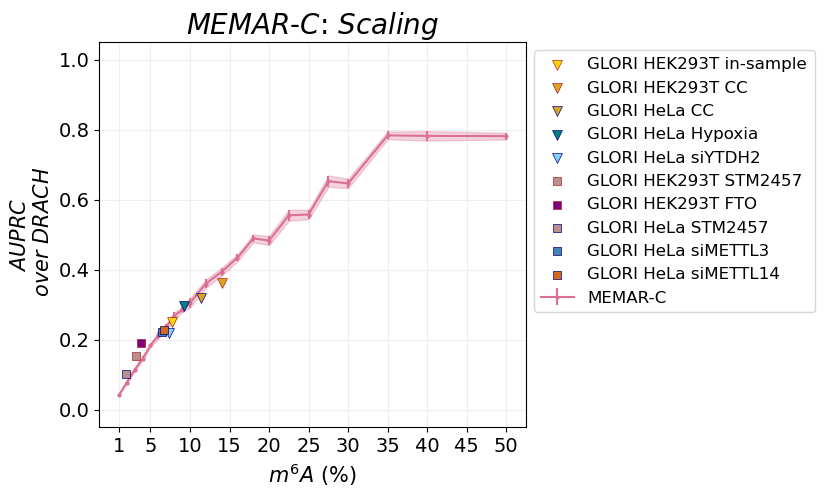

In [44]:
close("all")
figure(figsize=(5.5, 5))
#MEMAR-C scaling 
errorbar(rat ,av_C, yerr=st_C, marker="o", markersize=2, color="palevioletred", label="MEMAR-C",)
fill_between(rat , av_C.-st_C, av_C .+ st_C, color="palevioletred", alpha=0.3)
#MEMAR-C predictions over considered test datasets
scatter(perc_Infer, A_Infer, marker="v", color="gold", s=50,zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T in-sample")
scatter(perc_HEK_CC, A_HEK_CC, marker="v", s=50,zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T CC", color="goldenrod")
scatter(perc_HELA_CC, A_HELA_CC, marker="v", s=50,zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa CC", color="goldenrod")
scatter(perc_HPX, A_HPX, marker="v",s=50, zorder=3,color="teal", edgecolor="navy", linewidth=0.5, label="GLORI HeLa Hypoxia")
scatter(perc_YTH, A_YTH,marker="v",s=50, color="lightskyblue",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa siYTDH2")
scatter(perc_HEK_STM, A_HEK_STM,marker="s",s=30, color="rosybrown",zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T STM2457 ")
scatter(perc_HEK_FTO, A_HEK_FTO,marker="s",s=30, color="purple",zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T FTO")
scatter(perc_HELA_STM, A_HELA_STM,marker="s",s=30, color="rosybrown",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa STM2457")
scatter(perc_MET3, A_MET3,marker="s",s=30, color="steelblue",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa siMETTL3")
scatter(perc_MET14, A_MET14,marker="s",s=30, color="chocolate",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa siMETTL14")
xticks(fontsize=14)
yticks(fontsize=14)
legend(bbox_to_anchor=(1,1),fontsize=12)
title("\$MEMAR\$-\$C\$: \$Scaling\$ ",size=20)
xlabel(L"m^6A \ (\%)", size=15)
ylabel("\$AUPRC\$ \n \$ over \\ DRACH \$", size=15)
xticks([0.01, 0.05,0.1, 0.15, 0.2, 0.25,0.3, 0.35, 0.4, 0.45, 0.5],[1, 5,10, 15, 20, 25,30, 35, 40,45,  50])
ylim(-0.05, 1.05)
grid(alpha=0.2)
gcf()

## Two-state Model 

We address in this part the scaling of MEMAR model by a theoretical two-state dynamical model which describes the methylation process as a stochastich one, in which writers and ereasers can methylate or de-methylate a given site with a given probability. This probability will only depend parametrically on the statistics of 8-mers motifs. 


The two-state model needs the wrtiers/ereasers binding constants. These will be choosen starting from MEMAR-C inference dataset over HEK293T.

In [45]:
#Scoring all the 8-mers motifs
score_8mers=score_8_mers(M5, M6, Ava/100);
Dict_all8=Dict() #Initialization of a Dictionary
[Dict_all8[mots_list8[i][1:4]*'A'*mots_list8[i][5:8]]=score_8mers[i] for i in sortperm(score_8mers, rev=true)]; #Dictionary containing 

In [46]:
#Saving the probabilities into a dataframe
Df_Probability=DataFrame(Motifs=collect(keys(Dict_all8)), Probabilty=collect(values(Dict_all8))); 
#Ordering the dataframes in decreasing methylation proability
so=sortperm(Df_Probability[:, 2], rev=true);
Df_Probability[:, 1]=[Df_Probability[i,1] for i in so];
Df_Probability[:, 2]=[Df_Probability[i,2] for i in so];

In [47]:
#Scoring all DRACH motifs
score=score_DRACH(M5, M6, Dict_DRACH, Ava/100)
score_D=[score[DRACH[i][1:2]*DRACH[i][4:5]] for i in 1:length(DRACH)]
#Ordering DRACH motifs based on decreasing order of the methylation proabability
sort_D=sortperm(score_D, rev=true );
list_mots_D=DRACH[sort_D]; #ordered list of DRACH motifs

In [48]:
#Saving the probability of 8-mers DRACH motifs, the corresponding list in decresing order of methylation probability, 
#the position in the dataframe and the index of indexing for each 8-mers containing a DRACH motif following list_mots_D order 
p0, list_mots, pos, ind=probability_8DRACH(Df_Probability, Dict_DRACH, list_mots_D)
#Counting the amount of 8-mers DRACH motifs in the dataset, considering the common set of transcripts in control conditions
NN=[sum([count(b, test_HEK[a].sequence, overlap=true) for a in keys(MAP_mRNA)]) for b in list_mots];

In [49]:
#Two-state model Parameters: 
time=1000000000 #Time
kon=p0 #Writers binding constants
koff=(1 .-p0); #Ereasrs binding contants

In [50]:
"""Computing two-state model at equilibirum"""
fact=vcat(0.05:0.01:10...) #Considering uniform rescaling of ereaser binding constant
xt,At=[],[] 
#Looping over different ratio of methylated and non-methylated sites
for a in fact
    #Computing the AUPRC taking as ground truth the two-state model
    AUC, pm=AUC_t([time], kon, koff.*a, list_mots, NN)
    #Saving the percentage of methylated sites 
    push!(xt,pm)
    #Saving the AUPRC
    push!(At, AUC)
end

Plotting resulting curves

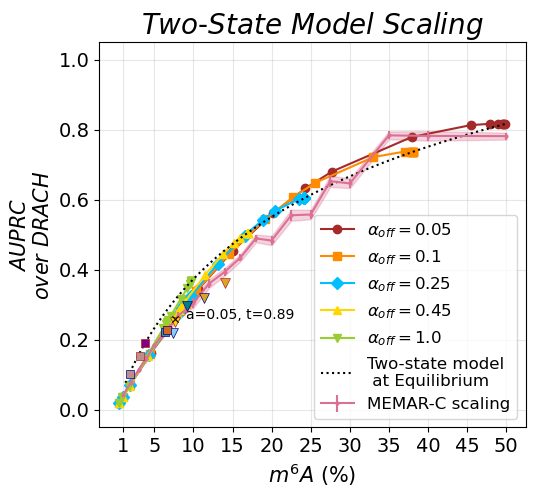

In [51]:
close("all")
cc=reverse(["yellowgreen", "gold","deepskyblue", "darkorange","brown",])
ss=["o", "s", "D", "^", "v"];
figure(figsize=(5.5, 5))
"""Computing two-state model out-of-equilibrium"""
fact=[0.05, 0.1,0.25,0.45, 1]
tim=[0.05, 0.1, 0.2, 0.5, 1.0,1.1,1.15, 1.2, 1.3, 2.0, 3.0, 4.0, 5.0, 10, 20, 30, 40, 50, 60, 70, 1000000000]
i=1

for a in fact
    AUC, pm=AUC_t(tim, kon, koff.*a, list_mots, NN)
    plot(pm, AUC, "-$(ss[i])", color=cc[i], label="\$\\alpha_{off}=\$$a")
    i+=1
end
"""Out-of equilibrium Description of in-test HEK293T"""
a=0.05
tt=vcat(0.1:0.005:1.5)
AUC, pm=AUC_t(tt, kon, koff.*a, list_mots, NN)
pmx=pm[argmin(abs.(pm.-perc_Infer))]
AUCx=AUC[argmin(abs.(pm.-perc_Infer))]
ttx=tt[argmin(abs.(pm.-perc_Infer))]
time_dependence=0.885
scatter(pmx, AUCx, s=20, marker="x", color="black", zorder=10, lw=0.8)
text(pmx-0.001+0.015, AUCx, "a=0.05, t=$(ttx)")
xticks([0.01, 0.05,0.1, 0.15, 0.2, 0.25,0.3, 0.35, 0.4, 0.45, 0.5],[1, 5,10, 15, 20, 25,30, 35, 40,45,  50],size=14)
yticks(size=14)
xlabel("\$m^6A\$ (%)", size=15)
ylabel("\$AUPRC\$\n\$over \\ DRACH\$", size=15)
title("\$Two\$-\$State\$ \$Model\$ \$Scaling\$", size=20)
errorbar(rat ,av_C, yerr=st_C, marker="o", markersize=2, color="palevioletred", label="MEMAR-C scaling",)
plot(xt, vcat(At...), color="black", label="Two-state model\n at Equilibrium", ls=":")
legend(fontsize=12)
ylim(-0.05, 1.05)
grid(alpha=0.3)
#MEMAR-C Scaling
fill_between(rat , av_C.-st_C, av_C .+ st_C, color="palevioletred", alpha=0.3)
scatter(perc_Infer, A_Infer, marker="v", color="gold", s=50,zorder=3,edgecolor="firebrick", linewidth=0.5)
#MEMAR-C predictions over test datasets
scatter(perc_HEK_CC, A_HEK_CC, marker="v", s=50,zorder=3,edgecolor="firebrick", linewidth=0.5,  color="goldenrod")
scatter(perc_HELA_CC, A_HELA_CC, marker="v", s=50,zorder=3,edgecolor="navy", linewidth=0.5,   color="goldenrod")
scatter(perc_HPX, A_HPX, marker="v",s=50, zorder=3,color="teal", edgecolor="navy", linewidth=0.5, )
scatter(perc_YTH, A_YTH,marker="v",s=50, color="lightskyblue",zorder=3,edgecolor="navy", linewidth=0.5, )
scatter(perc_HEK_STM, A_HEK_STM,marker="s",s=30, color="rosybrown",zorder=3,edgecolor="firebrick", linewidth=0.5, )
scatter(perc_HEK_FTO, A_HEK_FTO,marker="s",s=30, color="purple",zorder=3,edgecolor="firebrick", linewidth=0.5, )
scatter(perc_HELA_STM, A_HELA_STM,marker="s",s=30, color="rosybrown",zorder=3,edgecolor="navy", linewidth=0.5, )
scatter(perc_MET3, A_MET3,marker="s",s=30, color="steelblue",zorder=3,edgecolor="navy", linewidth=0.5, )
scatter(perc_MET14, A_MET14,marker="s",s=30, color="chocolate",zorder=3,edgecolor="navy", linewidth=0.5)
gcf()

### MEMAR-XT

Scoring all test datasets using MEMAR-XT model:

In [52]:
#Control Conditions:
score_met_ps_ds_pm_Infer,score_not_met_ps_ds_pm_Infer=score_ps_ds_pm_DRACH(M5, M6, test_HEK_Infer, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not]);
score_met_ps_ds_pm_HEK_CC,score_not_met_ps_ds_pm_HEK_CC=score_ps_ds_pm_DRACH(M5, M6, test_HEK, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not]);
score_met_ps_ds_pm_HELA_CC,score_not_met_ps_ds_pm_HELA_CC=score_ps_ds_pm_DRACH(M5, M6, test_HELA, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not]);
#Altered methylation codnitions
score_met_ps_ds_pm_HEK_FTO,score_not_met_ps_ds_pm_HEK_FTO,_=score_ps_ds_pm_DRACH(M5, M6, Test_HEK_FTO, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])
score_met_ps_ds_pm_MET3,score_not_met_ps_ds_pm_MET3,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_siMETTL3, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])
score_met_ps_ds_pm_MET14,score_not_met_ps_ds_pm_MET14,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_siMETTL14, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])
score_met_ps_ds_pm_YTH,score_not_met_ps_ds_pm_YTH,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_siYTDH, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])
score_met_ps_ds_pm_HELA_STM,score_not_met_ps_ds_pm_HELA_STM,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_STM2457, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])
score_met_ps_ds_pm_HEK_STM,score_not_met_ps_ds_pm_HEK_STM,_=score_ps_ds_pm_DRACH(M5, M6, Test_HEK_STM2457, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])
score_met_ps_ds_pm_HPX,score_not_met_ps_ds_pm_HPX,_=score_ps_ds_pm_DRACH(M5, M6, Test_HELA_HPX, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not])

(Any[Any[], Any[0.1382162414127133, 0.026687639796118486, 0.005484155627415236], Any[0.3436292422403949, 0.14021658305302798, 0.28732589089429755, 0.08283782738672274, 0.21046466821417847, 0.07524274267075667, 0.07993970835747834, 0.31845992462791667, 0.12471407405492099, 0.6176367348520634  …  0.45860608839056266, 0.4515264177227897, 0.6093423449362998, 0.1865890512915555, 0.39314408275702695, 0.2586950381403431, 0.1789863721103162, 0.2019541346500867, 0.0670860754858377, 0.4323447123179446], Any[0.34962678871034936, 0.38249021519424137, 0.62934647044676, 0.6675153606746979, 0.06466868427840776, 0.38326293328029654, 0.4037955674663356, 0.11600114189485689, 0.22463642962753752, 0.11989655536008774, 0.18468793283485488, 0.4478108674422202, 0.12815658966872898, 0.1202953031872848, 0.1590869875129859], Any[0.3777588635817711, 0.251119301744245, 0.7469522654407542], Any[0.6398909529470463, 0.4857792549363084], Any[0.24607103879825265, 0.6322589554842347, 0.4667167828770536, 0.6468525801181

In [53]:
#Scaling MEMAR-XT
av_XT, st_XT=scaling(score_met_ps_ds_pm_Infer, score_not_met_ps_ds_pm_Infer, rat, Ns, L );

In [54]:
#MEMAR-XT AUPRC: Control Conditions
_,_, A_HEK_CC_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_HEK_CC...), shuffle!(vcat(score_not_met_ps_ds_pm_HEK_CC...)),  "goldenrod","MEMAR-C HEK293T CC"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HELA_CC_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_HELA_CC...), shuffle!(vcat(score_not_met_ps_ds_pm_HELA_CC...)),  "steelblue","MEMAR-C HeLa CC"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_Infer_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_Infer...), shuffle!(vcat(score_not_met_ps_ds_pm_Infer...)),  "purple","MEMAR-C HEK293T Inference"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
#MEMAR-XT AUPRC: Altered methylations conditions
_,_, A_HEK_FTO_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_HEK_FTO...), shuffle!(vcat(score_not_met_ps_ds_pm_HEK_FTO...)),  "pink","MEMAR-C HEK293T FTO"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_MET3_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_MET3...), shuffle!(vcat(score_not_met_ps_ds_pm_MET3...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_MET14_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_MET14...), shuffle!(vcat(score_not_met_ps_ds_pm_MET14...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_YTH_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_YTH...), shuffle!(vcat(score_not_met_ps_ds_pm_YTH...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HELA_STM_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_HELA_STM...), shuffle!(vcat(score_not_met_ps_ds_pm_HELA_STM...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HEK_STM_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_HEK_STM...), shuffle!(vcat(score_not_met_ps_ds_pm_HEK_STM...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)
_,_, A_HPX_XT,_=plot_PR_score(vcat(score_met_ps_ds_pm_HPX...), shuffle!(vcat(score_not_met_ps_ds_pm_HPX...)),  "lightskyblue","MEMAR-C HEK293T siMETTL3"; xx=0.0,pas=0.005, ls="-",mark="*", verbose=true)

(Figure(PyObject <Figure size 550x500 with 1 Axes>), 0.22, 0.4142675479833976, 0.4581203152027677)

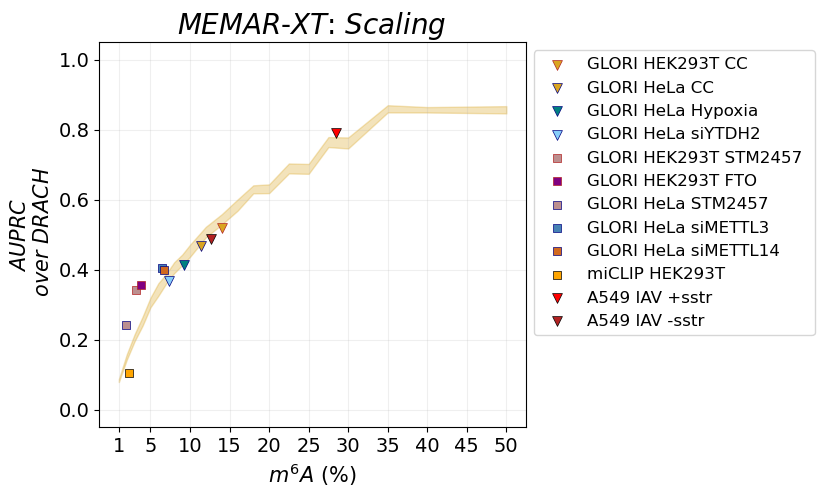

In [55]:
close("all")
figure(figsize=(5.5, 5))
"""MEMAR-XT Scaling"""
errorbar(rat ,av_XT, yerr=st_XT, marker="o", markersize=2, color="goldenrod", label="MEMAR-XT scaling")
fill_between(rat , av_XT.-st_XT, av_XT .+ st_XT, color="goldenrod", alpha=0.3)
"""MEMAR-XT: predictions over test datasets"""
scatter(perc_Infer, A_Infer_XT, marker="v", s=50,zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T in-sample", color="gold")
scatter(perc_HEK_CC, A_HEK_CC_XT, marker="v", s=50,zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T CC", color="goldenrod")
scatter(perc_HELA_CC, A_HELA_CC_XT, marker="v", s=50,zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa CC", color="goldenrod")
scatter(perc_HPX, A_HPX_XT, marker="v",s=50, zorder=3,color="teal", edgecolor="navy", linewidth=0.5, label="GLORI HeLa Hypoxia ")
scatter(perc_YTH, A_YTH_XT,marker="v",s=50, color="lightskyblue",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa siYTDH2")
scatter(perc_HEK_STM, A_HEK_STM_XT,marker="s",s=30, color="rosybrown",zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T STM2457 ")
scatter(perc_HEK_FTO, A_HEK_FTO_XT,marker="s",s=30, color="purple",zorder=3,edgecolor="firebrick", linewidth=0.5,  label="GLORI HEK293T FTO ")
scatter(perc_HELA_STM, A_HELA_STM_XT,marker="s",s=30, color="rosybrown",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa STM2457")
scatter(perc_MET3, A_MET3_XT,marker="s",s=30, color="steelblue",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa siMETTL3 ")
scatter(perc_MET14, A_MET14_XT,marker="s",s=30, color="chocolate",zorder=3,edgecolor="navy", linewidth=0.5,  label="GLORI HeLa siMETTL14")
scatter(0.0228, 0.10573, marker="s", s=30,zorder=3,edgecolor="black", linewidth=0.5,  color="orange", label="miCLIP HEK293T")
scatter(0.2843, 0.789, marker="v", s=50, color="red", zorder=3, edgecolor="black", linewidth=0.5, label="A549 IAV +sstr")
scatter(0.12644, 0.487,marker="v",s=50, zorder=3,color="firebrick",edgecolor="black", linewidth=0.5,  label="A549 IAV -sstr")
xticks(fontsize=14)
yticks(fontsize=14)
legend(bbox_to_anchor=(1,1),fontsize=12)
title("\$MEMAR\$-\$XT\$: \$Scaling\$ ",size=20)
xlabel(L"m^6A \ (\%)", size=15)
ylabel("\$AUPRC\$ \n \$ over \\ DRACH \$", size=15)
xticks([0.01, 0.05,0.1, 0.15, 0.2, 0.25,0.3, 0.35, 0.4, 0.45, 0.5],[1, 5,10, 15, 20, 25,30, 35, 40,45,  50])
ylim(-0.05, 1.05)
grid(alpha=0.2)
gcf()

### Uniform-rescaling from inferred  dataset of the two-states model

We asses here the variations of the the two-state model, either uniformly-increasing the ereaser binding constant or decreasing the writer ones. These uniform-variations corrrespond to an increase of the concentratio of the ereaser/writer proteins:

In [63]:
#We compute the predicted probability of marginalized DRACH motifs from the learnt model
p0_marg=[marginalized_prob_MET(M5, M6, Ava/100, b[1:2]*b[4:5]) for b in list_mots_D];

We then train a MEMAR-C model for each given dataset (selecting only trascnripts which were used for training set if  present).

In [57]:
#HEK293T
p_HEK_CC=eq_prob_MarG(test_HEK,train, list_mots_D);
p_HEK_STM=eq_prob_MarG(test_HEK_STM2457, train,list_mots_D);
p_HEK_FTO=eq_prob_MarG(test_HEK_FTO, train,list_mots_D);
#HeLa
p_HELA_CC=eq_prob_MarG(test_HELA, train,list_mots_D);
p_HELA_siMETTL3=eq_prob_MarG(test_HELA_siMETTL3, train,list_mots_D);
p_HELA_siMETTL14=eq_prob_MarG(test_HELA_siMETTL14, train,list_mots_D);
p_HELA_HPX=eq_prob_MarG(test_HELA_HPX, train,list_mots_D);
p_HELA_YTH=eq_prob_MarG(test_HELA_siYTDH, train,list_mots_D);
p_HELA_STM=eq_prob_MarG(test_HELA_STM2457, train,list_mots_D);

Converged at iteration 215, where the maximum error is 9.891563617122961e-6
Converged at iteration 135, where the maximum error is 9.863513525246777e-6
Converged at iteration 227, where the maximum error is 9.911981991379305e-6
Converged at iteration 143, where the maximum error is 9.969059689442922e-6
Converged at iteration 219, where the maximum error is 9.856927402995018e-6
Converged at iteration 128, where the maximum error is 9.997414452703364e-6
Converged at iteration 217, where the maximum error is 9.832740217981782e-6
Converged at iteration 144, where the maximum error is 9.770995392832053e-6
Converged at iteration 214, where the maximum error is 9.967255615192256e-6
Converged at iteration 129, where the maximum error is 9.69282851747029e-6
Converged at iteration 214, where the maximum error is 9.897677929307665e-6
Converged at iteration 154, where the maximum error is 9.775566710885312e-6
Converged at iteration 204, where the maximum error is 9.793737097298257e-6
Converged at 

We consider than the two state model, with the same $k_{on}$ and $k_{off}$ previously used, directly coming form MEMAR-C inferred in the training dataset of HEK293T, considering only the equilibirum condition

In [58]:
#Going back to the equilibrium curve selecting a high value of time to mimic t->inf
time_dependence=10000000000
#Treshold choosen to compare the compatibility between MEMAR-C inferred in a given dataset and the uniform rescaled two-state model
tresh_c=[0.005,0.015,0.03];
#Amount of DRACH motifs amongst all 8-mers DRACH motifs, following the order of list_mots_D
N_DRACH=[sum(NN[ind[i]]) for i in 1:length(list_mots_D)];

#### HEK293T Control Conditions

In [64]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to control conditions (obtained in deep sequecing)
x_opt_HEK_CC=Infer_uniform(p0_marg, p_HEK_CC, time_dependence);
#Initialzation 
PU_HEK_CC=[] 
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HEK_CC, [parameter_p(p0_marg, time_dependence, i,j, x_opt_HEK_CC; verb=true) for j in 1:3]) for i in 1:18];

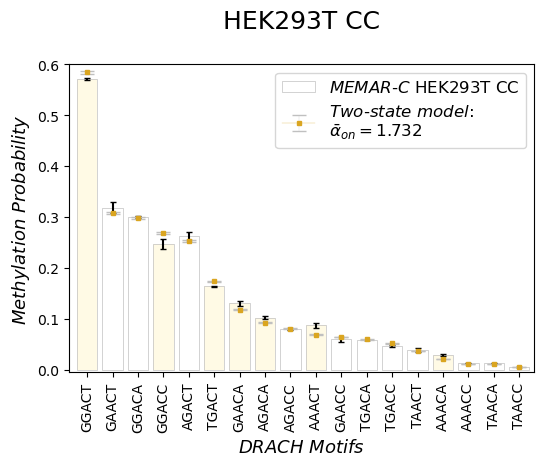

In [65]:
close("all")
figure(figsize=(6, 4))
title("HEK293T CC\n", size=18)
AA=explanation_degree_param(PU_HEK_CC, [[hcat(p_HEK_CC...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]),  color="gold", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HEK_CC[i]),yerr=std(PU_HEK_CC[i]), marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HEK293T CC" )
errorbar("TTTTT",+21,1, marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(x_opt_HEK_CC)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.6)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HeLa Contol Conditions:

In [121]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to control conditions (obtained in deep sequencing)
HEK_to_HELA_CC_S=Infer_uniform(p0_marg, p_HELA_CC, time_dependence;);
#Initialzation
PU_HELA_CC_S=[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_CC_S, [parameter_p(p0_marg, time_dependence, i,j, HEK_to_HELA_CC_S;verb=true, ) for j in 1:3]) for i in 1:18];

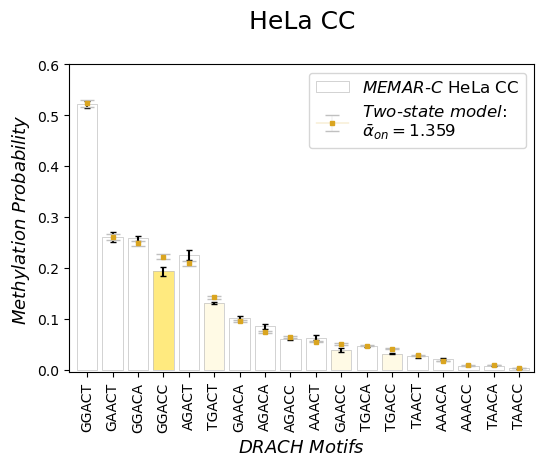

In [122]:
close("all")
figure(figsize=(6, 4))
title("HeLa CC\n", size=18)
AA=explanation_degree_param(PU_HELA_CC_S, [[hcat(p_HELA_CC...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]),  color="gold", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_CC_S[i]),yerr=std(PU_HELA_CC_S[i]), marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="rosybrown", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{STM2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{CC}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_STM)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa CC" )
errorbar("TTTTT",+21,1, marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HEK_to_HELA_CC_S)))\$ ")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.6)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HeLa STM2457

In [123]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to altered condition
HELA_to_STM_S=Infer_uniform(p0_marg, p_HELA_STM, time_dependence; );
#Initialzation
PU_HELA_STM_S=[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_STM_S, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_STM_S; verb=true) for j in 1:3]) for i in 1:18];

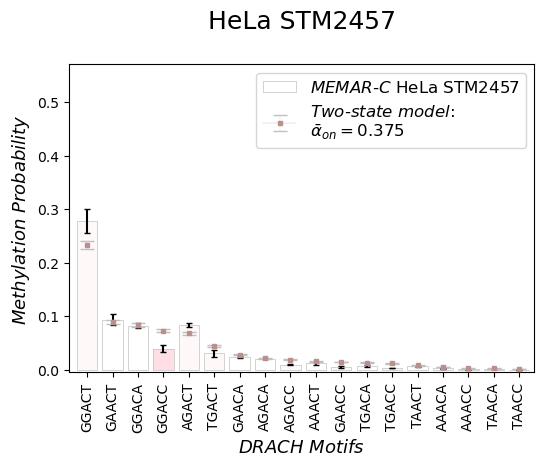

In [124]:
close("all")
figure(figsize=(6, 4))
title("HeLa STM2457\n", size=18)
AA=explanation_degree_param(PU_HELA_STM_S, [[hcat(p_HELA_STM...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_STM...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_STM...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_STM...)[i, j]) for j in 1:3]),  color="pink", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_STM_S[i]),yerr=std(PU_HELA_STM_S[i]), marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa STM2457" )
errorbar("TTTTT",+21,1, marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_STM_S)))\$ ")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HEK293T STM2457

In [125]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to altered condition
HEK_to_STM_S=Infer_uniform(p0_marg, p_HEK_STM, time_dependence;);
#Initialzation
PU_HEK_STM_S=[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HEK_STM_S, [parameter_p(p0_marg, time_dependence, i,j, HEK_to_STM_S; verb=true) for j in 1:3]) for i in 1:18];

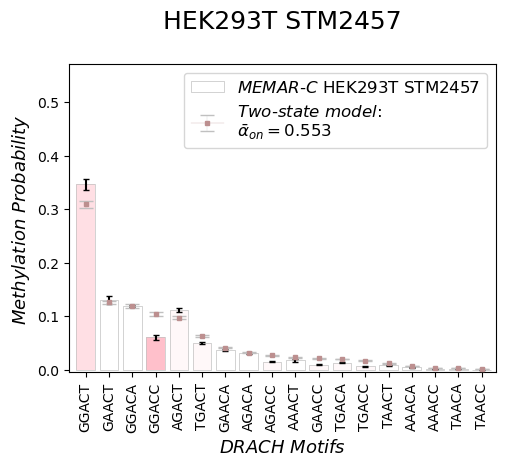

In [126]:
close("all")
figure(figsize=(5.5, 4))
title("HEK293T STM2457\n", size=18)
AA=explanation_degree_param(PU_HEK_STM_S, [[hcat(p_HEK_STM...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HEK_STM...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HEK_STM...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HEK_STM...)[i, j]) for j in 1:3]),  color="pink", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HEK_STM_S[i]),yerr=std(PU_HEK_STM_S[i]), marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HEK293T STM2457" )
errorbar("TTTTT",+21,1, marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HEK_to_STM_S)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HeLa Hypoxia  

In [127]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to altered condition
HELA_to_HPX_S=Infer_uniform(p0_marg, p_HELA_HPX, time_dependence; );
#Initialzation
PU_HELA_HPX_S=[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_HPX_S, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_HPX_S; verb=true) for j in 1:3]) for i in 1:18];

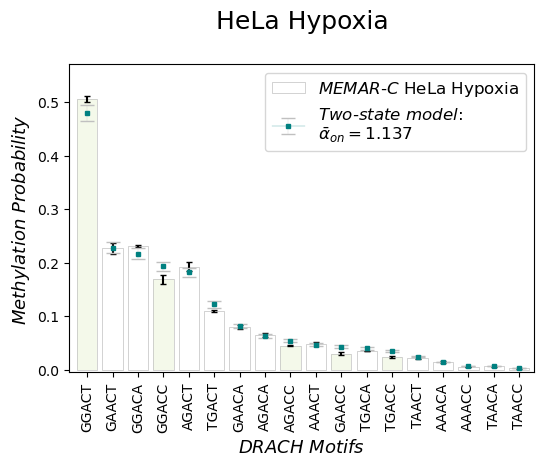

In [128]:
close("all")
figure(figsize=(6, 4))
title("HeLa Hypoxia\n", size=18)
AA=explanation_degree_param(PU_HELA_HPX_S, [[hcat(p_HELA_HPX...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_HPX...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_HPX...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_HPX...)[i, j]) for j in 1:3]),  color="yellowgreen", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_HPX_S[i]),yerr=std(PU_HELA_HPX_S[i]), marker="s", color="teal", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa Hypoxia")
errorbar("TTTTT",+21,1, marker="s", color="teal", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_HPX_S)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HeLa siYTHDF2

In [129]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to altered condition
HELA_to_YTH_S=Infer_uniform(p0_marg, p_HELA_YTH, time_dependence; );
#Initialzation
PU_HELA_YTH_S=[],[],[],[],[],[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_YTH_S, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_YTH_S; verb=true) for j in 1:3]) for i in 1:18];

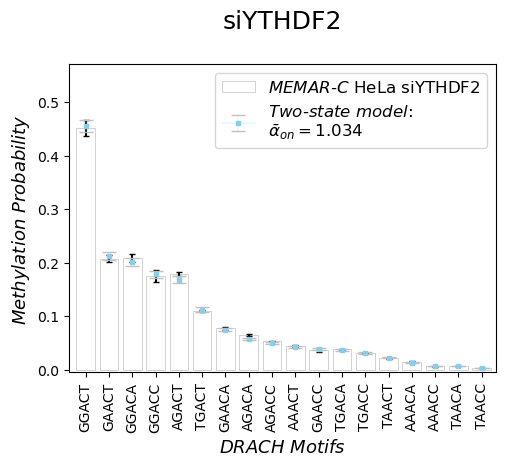

In [130]:
close("all")
figure(figsize=(5.5, 4))
title("siYTHDF2\n", size=18)
AA=explanation_degree_param(PU_HELA_YTH_S, [[hcat(p_HELA_YTH...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_YTH...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_YTH...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_YTH...)[i, j]) for j in 1:3]),  color="powderblue", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_YTH_S[i]),yerr=std(PU_HELA_YTH_S[i]), marker="s", color="skyblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
\bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa siYTHDF2" )
errorbar("TTTTT",+21,1, marker="s", color="skyblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_YTH_S)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HeLa siMETTL3

In [131]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to altered condition
HELA_to_siMETTL3_S=Infer_uniform(p0_marg, p_HELA_siMETTL3, time_dependence; );
#Initialzation
PU_HELA_siMETTL3_S=[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_siMETTL3_S, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_siMETTL3_S; verb=true) for j in 1:3]) for i in 1:18];

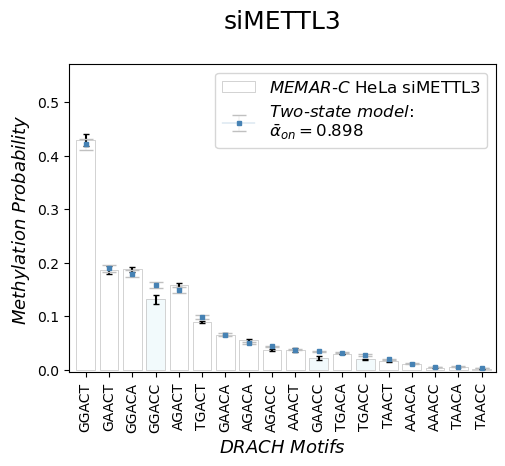

In [132]:
close("all")
figure(figsize=(5.5, 4))
title("siMETTL3\n", size=18)
AA=explanation_degree_param(PU_HELA_siMETTL3_S, [[hcat(p_HELA_siMETTL3...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL3...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_siMETTL3...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL3...)[i, j]) for j in 1:3]),  color="skyblue", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_siMETTL3_S[i]),yerr=std(PU_HELA_siMETTL3_S[i]), marker="s", color="steelblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
\bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa siMETTL3" )
errorbar("TTTTT",+21,1, marker="s", color="steelblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_siMETTL3_S)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HeLa siMETTL14

In [133]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to altered condition
HELA_to_siMETTL14_S=Infer_uniform(p0_marg, p_HELA_siMETTL14, time_dependence; );
#Initialzation
PU_HELA_siMETTL14_S=[],[],[],[],[],[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_siMETTL14_S, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_siMETTL14_S;verb=true) for j in 1:3]) for i in 1:18];

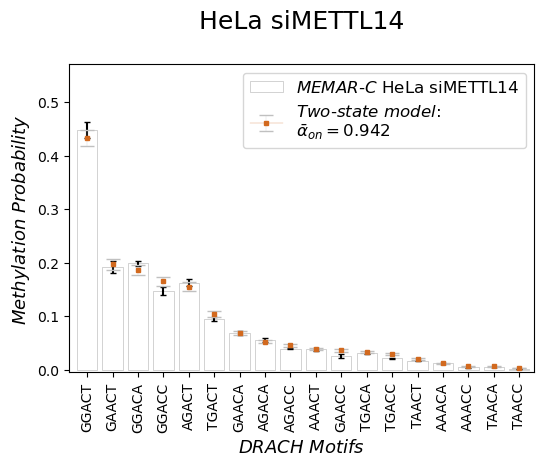

In [134]:
close("all")
figure(figsize=(6, 4))
title("HeLa siMETTL14\n", size=18)
AA=explanation_degree_param(PU_HELA_siMETTL14_S, [[hcat(p_HELA_siMETTL14...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL14...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_siMETTL14...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL14...)[i, j]) for j in 1:3]),  color="sandybrown", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_siMETTL14_S[i]),yerr=std(PU_HELA_siMETTL14_S[i]), marker="s", color="chocolate", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
\bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label=label="\$MEMAR\$-\$C\$ HeLa siMETTL14" )
errorbar("TTTTT",+21,1, marker="s", color="chocolate", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_siMETTL14_S)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

#### HEK293T FTO

In [135]:
#Computing the uniform-rescaling of the Ereaser binding constant from inferred dataset to altered condition
HEK_to_FTO_S=Infer_uniform_FTO(p0_marg, p_HEK_FTO, time_dependence;);
#Initialzation
PU_HEK_FTO_S=[],[],[],[],[],[]
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HEK_FTO_S, [parameter_p_FTO(p0_marg, time_dependence, i,j, HEK_to_FTO_S; verb=true) for j in 1:3]) for i in 1:18];

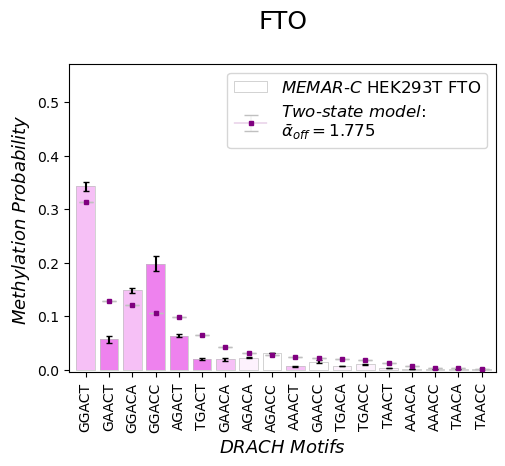

In [136]:
close("all")
figure(figsize=(5.5, 4))
title("FTO\n", size=18)
AA=explanation_degree_param(PU_HEK_FTO_S, [[hcat(p_HEK_FTO...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HEK_FTO...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HEK_FTO...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HEK_FTO...)[i, j]) for j in 1:3]),  color="violet", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HEK_FTO_S[i]),yerr=std(PU_HEK_FTO_S[i]), marker="s", color="purple", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="purple", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{FTO2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{FTO}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HEK_FTO)))")
bar("TTTTT",+21,   edgecolor="silver",  color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HEK293T FTO")
errorbar("TTTTT",+21,1, marker="s", color="purple", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{off}=$(round(digits=3, mean(HEK_to_FTO_S)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

$$\textcolor{firebrick}{SUPPLEMENTARY}$$

#### 1) Scaling on DRACH motifs

We show the saling of remaining MEMAR Model (XC and T), to assess the scaling of perfomance at different imbalance ratio

In [141]:
"""MEMAR-XC model"""
#Scoring all DRACH motifs
score_met_ps_ds_Infer,score_not_met_ps_ds_Infer=score_ps_ds_pm_DRACH(M5, M6, test_HEK_Infer, keys(MAP_mRNA), constant_prior; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not]);
#Computing the scaling selecting sub-partition of amongst the givent test set
av_XC, st_XC=scaling(score_met_ps_ds_Infer, score_not_met_ps_ds_Infer, rat, Ns, L);
"""MEMAR-T model"""
#Scoring all DRACH motifs
score_met_ps_pm_Infer,score_not_met_ps_pm_Infer=score_ps_ds_pm_DRACH(M5, M6, test_HEK_Infer, keys(MAP_mRNA), prior_HEK;);
#Computing the scaling selecting sub-partition of amongst the givent test set
av_T, st_T=scaling(score_met_ps_pm_Infer, score_not_met_ps_pm_Infer, rat, Ns , L);


#### 2) Scaling on all motifs

We now assess the recaling over all motifs (not filtering therefore only DRACH motifs), for all MEMAR models

In [142]:
"""Scoring all motifs in the given dataset using all MEMAR-models"""
#MEMAR-XC
score_met_ps_ds_Infer_all,score_not_met_ps_ds_Infer_all=score_ps_ds_pm(M5, M6, test_HEK_Infer, keys(MAP_mRNA), constant_prior; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not]);
#MEMAR-T
score_met_ps_pm_Infer_all,score_not_met_ps_pm_Infer_all=score_ps_ds_pm(M5, M6, test_HEK_Infer, keys(MAP_mRNA), prior_HEK;);
#MEMAR-XT
score_met_ps_ds_pm_Infer_all,score_not_met_ps_ds_pm_Infer_all=score_ps_ds_pm(M5, M6, test_HEK_Infer, keys(MAP_mRNA), prior_HEK; verb=true, map=MAP_mRNA,d_met=[x_met, y_met], d_not=[x_not, y_not]);
#MEMAR-C
score_met_ps_Infer_all,score_not_met_ps_Infer_all=score_ps_ds_pm(M5, M6, test_HEK_Infer, keys(MAP_mRNA), constant_prior)

(Any[Any[0.20521841412623024], Any[0.2772207187465872, 0.24953115274010082, 0.19827111470678704, 0.0496579424121737], Any[0.3239208761672392, 0.13017200732906745, 0.2750539644650613, 0.19331336280263506, 0.07031873733855801, 0.07351807246285984, 0.28779264578172903, 0.33368109451342076, 0.12885035353595004, 0.21983601652621537, 0.06328933650607886, 0.03049886430953104, 0.42352427330258585, 0.043398906389307365, 0.10971666035981303, 0.2954362650462276, 0.5946084259871002, 0.4001738447958105, 0.5515369848448393], Any[0.22702988581202127, 0.2712368042026734, 0.1462517821465417, 0.3250026029107922, 0.13541369236383674, 0.2542209200767527, 0.13180495689085422, 0.2047475690618474, 0.5065261219790521, 0.15483243476981282, 0.19887980763548102], Any[1.4542837420366589e-5, 0.1669435808662479, 0.105871489036249, 0.5737356762674186], Any[0.5062133908398633, 0.35598532592453674], Any[0.2705141267741914, 0.659850353356175, 0.006995702730589588, 0.45387739575272756, 0.49939364901565236, 0.17140896648

In [144]:
rat_all=[0.001, 0.003,  0.005, 0.007,0.009] # a lower ratio between methylated and non-methylated sites is considered since the imbalance is higher while considering all motifs
Ns_all=20 #Average quantities will be made considering 20 replicates
av_C_all, st_C_all=scaling(score_met_ps_Infer_all, score_not_met_ps_Infer_all, rat_all, Ns_all, L );
av_XC_all, st_XC_all=scaling(score_met_ps_ds_Infer_all, score_not_met_ps_ds_Infer_all, rat_all, Ns_all, L);
av_T_all, st_T_all=scaling(score_met_ps_pm_Infer_all, score_not_met_ps_pm_Infer_all, rat_all, Ns_all , L);
av_XT_all, st_XT_all=scaling(score_met_ps_ds_pm_Infer_all, score_not_met_ps_ds_pm_Infer_all, rat_all, Ns_all, L );

Plotting the resulting scaling curves

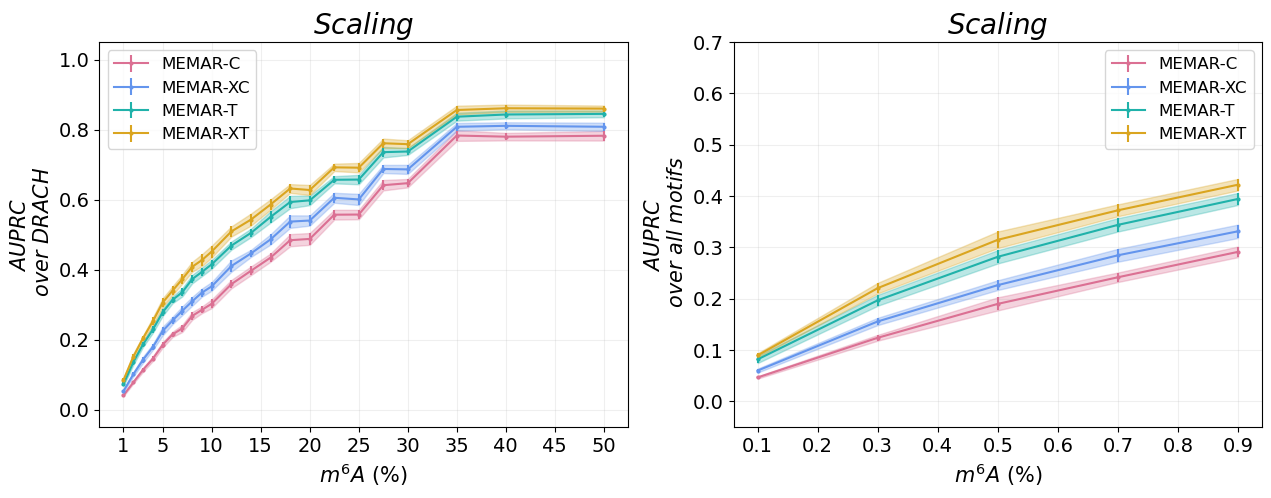

In [148]:
close("all")
figure(figsize=(15, 5))
subplot(1, 2, 1)
#MEMAR-C
errorbar(rat ,av_C, yerr=st_C, marker="o", markersize=2, color="palevioletred", label="MEMAR-C")
fill_between(rat , av_C.-st_C, av_C .+ st_C, color="palevioletred", alpha=0.3)
#MEMAR_XC
errorbar(rat ,av_XC, yerr=st_XC, marker="o", markersize=2, color="cornflowerblue", label="MEMAR-XC")
fill_between(rat , av_XC.-st_XC, av_XC.+ st_XC, color="cornflowerblue", alpha=0.3)
#MEMAR_T
errorbar(rat ,av_T, yerr=st_T, marker="o", markersize=2, color="lightseagreen", label="MEMAR-T")
fill_between(rat , av_T.-st_T, av_T.+ st_T, color="lightseagreen", alpha=0.3)
#MEMAR_XT
errorbar(rat ,av_XT, yerr=st_XT, marker="o", markersize=2, color="goldenrod", label="MEMAR-XT")
fill_between(rat , av_XT.-st_XT, av_XT.+ st_XT, color="goldenrod", alpha=0.3)

xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
title(L"Scaling ",size=20)
xlabel(L"m^6A \ (\%)", size=15)
ylabel("\$AUPRC\$ \n \$ over \\ DRACH \$", size=15)
xticks([0.01, 0.05,0.1, 0.15, 0.2, 0.25,0.3, 0.35, 0.4, 0.45, 0.5],[1, 5,10, 15, 20, 25,30, 35, 40,45,  50])
ylim(-0.05, 1.05)
grid(alpha=0.2)

subplot(1, 2, 2)
#MEMAR-C
errorbar(rat_all ,av_C_all, yerr=st_C_all, marker="o", markersize=2, color="palevioletred", label="MEMAR-C")
fill_between(rat_all , av_C_all.-st_C_all, av_C_all .+ st_C_all, color="palevioletred", alpha=0.3)
#MEMAR_XC
errorbar(rat_all ,av_XC_all, yerr=st_XC_all, marker="o", markersize=2, color="cornflowerblue", label="MEMAR-XC")
fill_between(rat_all , av_XC_all.-st_XC_all, av_XC_all.+ st_XC_all, color="cornflowerblue", alpha=0.3)
#MEMAR_T
errorbar(rat_all ,av_T_all, yerr=st_T_all, marker="o", markersize=2, color="lightseagreen", label="MEMAR-T")
fill_between(rat_all , av_T_all.-st_T_all, av_T_all.+ st_T_all, color="lightseagreen", alpha=0.3)
#MEMAR_XT
errorbar(rat_all ,av_XT_all, yerr=st_XT_all, marker="o", markersize=2, color="goldenrod", label="MEMAR-XT")
fill_between(rat_all , av_XT_all.-st_XT_all, av_XT_all.+ st_XT_all, color="goldenrod", alpha=0.3)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
title(L"Scaling",size=20)
xlabel(L"m^6A \ (\%)", size=15)
ylabel("\$AUPRC\$ \n \$ over  \\ all \\ motifs\$", size=15)
ylim(-0.05, 0.7)
xticks([0.001, 0.002,0.003, 0.004, 0.005, 0.006,0.007, 0.008, 0.009],[0.1, 0.2,0.3, 0.4, 0.5, 0.6,0.7, 0.8, 0.9])
grid(alpha=0.2)
gcf()